In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Superstore.csv", encoding="latin-1")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [4]:
df.info()
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quanti

In [5]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Year-Month"] = df["Order Date"].dt.to_period("M")

In [6]:
print("Before:", df.shape)
df = df.drop_duplicates()
print("After:", df.shape)

Before: (10800, 24)
After: (10296, 24)


In [7]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Year-Month
0,1,CA-2017-152156,2017-11-08,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,2017.0,11.0,2017-11
1,2,CA-2017-152156,2017-11-08,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,2017.0,11.0,2017-11
2,3,CA-2017-138688,2017-06-12,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,2017.0,6.0,2017-06
3,4,US-2016-108966,2016-10-11,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,2016.0,10.0,2016-10
4,5,US-2016-108966,2016-10-11,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,2016.0,10.0,2016-10


In [8]:
df.groupby("Category")[["Sales", "Profit"]].sum()

,Sales,Profit
Category,,
Furniture,741999.7953,18451.2728
Office Supplies,719047.0320,122490.8008
Technology,836154.0330,145454.9481


In [9]:
df.groupby("Region")[["Sales", "Profit"]].sum()

,Sales,Profit
Region,,
Central,501239.8908,39706.3625
East,678781.2400,91522.7800
South,391721.9050,46749.4303
West,725457.8245,108418.4489


In [10]:
df.groupby("Segment")[["Sales", "Profit"]].sum()

,Sales,Profit
Segment,,
Consumer,1.161401e+06,134119.2092
Corporate,7.061464e+05,91979.1340
Home Office,4.296531e+05,60298.6785


In [11]:
df.groupby("Sub-Category")["Profit"].sum().sort_values()

,Profit
Sub-Category,
Tables,-17725.4811
Bookcases,-3472.5560
Supplies,-1189.0995
Fasteners,949.5182
Machines,3384.7569
Labels,5546.2540
Art,6527.7870
Envelopes,6964.1767
Furnishings,13059.1436


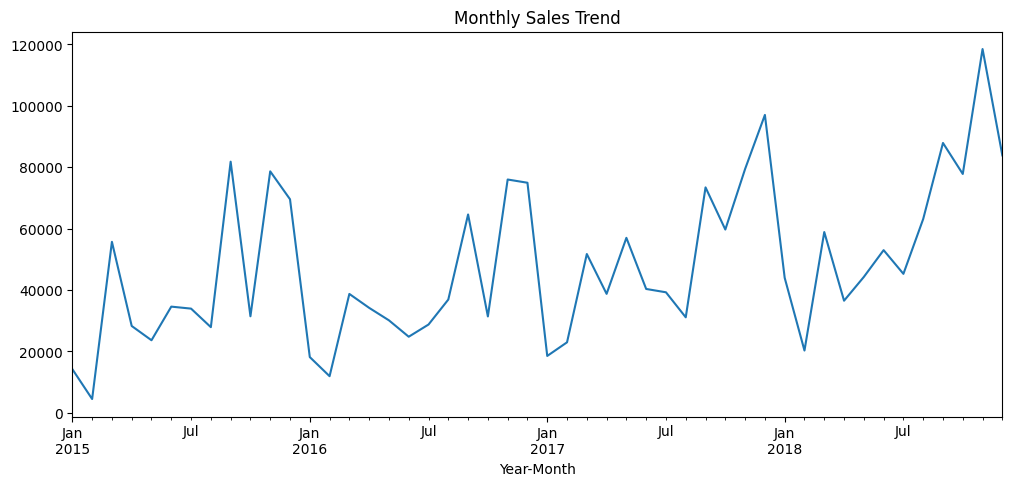

In [12]:
monthly = df.groupby("Year-Month")["Sales"].sum()
monthly.index = monthly.index.to_timestamp()
monthly.plot(figsize=(12,5), title="Monthly Sales Trend")
plt.show()

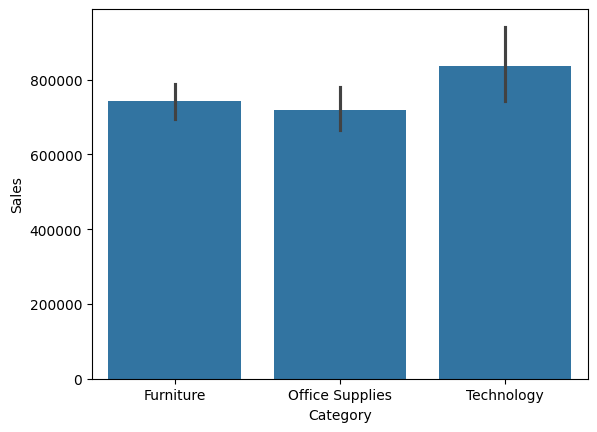

In [13]:
sns.barplot(data=df, x="Category", y="Sales", estimator=sum)
plt.show()

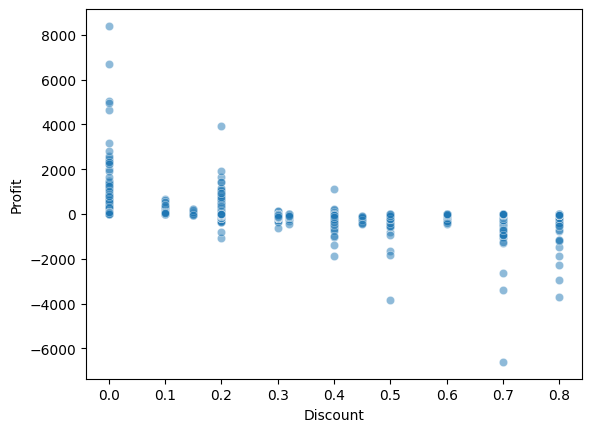

In [14]:
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.5)
plt.show()

In [15]:
df = df.dropna(subset=["Order Date", "Sales", "Profit"])
print(df.shape)

print(df.groupby("Month")["Sales"].sum().round(0).sort_values(ascending=False))

df["Discount_Band"] = pd.cut(df["Discount"], bins=[-0.01, 0, 0.1, 0.2, 0.3, 0.5, 1],
                             labels=["0%", "1-10%", "11-20%", "21-30%", "31-50%", "50%+"])
print(df.groupby("Discount_Band", observed=True)["Profit"].agg(["mean", "sum"]).round(2))

(9994, 24)
Month
11.0    352461.0
12.0    325294.0
9.0     307650.0
3.0     205005.0
10.0    200323.0
8.0     159044.0
5.0     155029.0
6.0     152719.0
7.0     147238.0
4.0     137762.0
1.0      94925.0
2.0      59751.0
Name: Sales, dtype: float64
                 mean        sum
Discount_Band                   
0%              66.90  320987.60
1-10%           96.06    9029.18
11-20%          24.74   91756.30
21-30%         -45.68  -10369.28
31-50%        -156.28  -48447.73
50%+           -89.44  -76559.05


## Executive Takeaways

1. **Seasonality:** Sales peak in November (352,461) and December (325,294), with September (307,650) also strong. February (59,751) and January (94,925) are the weakest months, so sales are heavily concentrated in the year-end period.
2. **Category:** Technology earns the highest profit (145,455, about 17.4% margin). Furniture has high sales (741,999) but only 18,451 in profit, a margin of about 2.5%.
3. **Discount impact:** Profit turns negative once discounts exceed 20%. The average profit per order line is 24.74 for 11-20% discounts, but -45.68 for 21-30% and -156.28 for 31-50%, so heavy discounting is eroding margins.
4. **Region:** The West leads in sales (725,458) and profit (108,418). The Central region has the weakest margin (about 7.9%), with only 39,706 profit on 501,240 in sales.
5. **Sub-Category:** Tables (-17,725), Bookcases (-3,473) and Supplies (-1,189) are loss-making. Tables is the biggest drag and needs a pricing and discount review.
6. **Segment:** Consumer is the largest segment, contributing about 1.16M in sales and 134,119 in profit.